<!-- open-in-badges -->
[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/06_foundation_models/notebooks/sesion_06_4_modelos_fundacionales.ipynb) [![Abrir en Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/06_foundation_models/notebooks/sesion_06_4_modelos_fundacionales.ipynb) [![Abrir en Lightning Studio](https://pl-bolts-doc-images.s3.us-east-2.amazonaws.com/app-2/studio-badge.svg)](https://lightning.ai/new?repo_url=https%3A%2F%2Fgithub.com%2FEAFIT-IA%2Fsi7011-DeepLearning%2Fblob%2Fmain%2Fsessions%2F06_foundation_models%2Fnotebooks%2Fsesion_06_4_modelos_fundacionales.ipynb)

# SI7011 · Sesión 06 · 4. Modelos fundacionales sin entrenar: CLIP y Chronos
**Juan David Martínez Vargas · Universidad EAFIT**

**Opcional, para la casa.** Acompaña la **Parte 4** de las diapositivas (55–59). Volvemos a dos problemas que ya resolviste, ahora con modelos preentrenados por otros a gran escala y usados **sin dar un solo paso de gradiente** sobre tus datos:

| Sección | Datos | Modelo | Contra qué |
|---|---|---|---|
| 1–3 | EuroSAT (sesiones 03 y 04) | CLIP zero-shot: la imagen contra un texto por clase | CLIP y ResNet-18 de ImageNet con sonda, 1 % y 10 % de las etiquetas |
| 4–5 | Bike Sharing (sesión 05) | Chronos-Bolt zero-shot: la serie como tokens | las líneas base y tu red del integrador 5.6, con sus mismas ventanas |

La pregunta es la de la diapositiva 58: **zero-shot es una afirmación que hay que comprobar**.

**Usa GPU** (Kaggle T4, unos 10 minutos) y activa **Internet** en *Settings*: CLIP y Chronos se bajan de Hugging Face y Bike Sharing de GitHub o UCI. EuroSAT: en Kaggle agrega `apollo2506/eurosat-dataset` con *Add Input* (el mismo de las sesiones 03 y 04); en Colab se baja con tu secreto `KAGGLE_API_TOKEN`.

In [1]:
# Kaggle trae torchao 0.10, que las versiones recientes de transformers y peft rechazan al importarse
# ("Found an incompatible version of torchao"). Este notebook no lo usa: si es viejo, se desinstala.
import os
from importlib.metadata import version, PackageNotFoundError
try:
    if tuple(int(x) for x in version('torchao').split('.')[:2]) < (0, 16):
        os.system('pip uninstall -y -q torchao')
except (PackageNotFoundError, ValueError):
    pass

import hashlib, json, math, os, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torchvision import datasets
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.model_selection import train_test_split

try:
    import transformers
    from chronos import BaseChronosPipeline
except ImportError:                                         # chronos-forecasting no viene instalado
    os.system('pip install -q transformers chronos-forecasting')
    import transformers
    from chronos import BaseChronosPipeline
from transformers import CLIPModel, CLIPProcessor

torch.manual_seed(0)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('PyTorch', torch.__version__, '· transformers', transformers.__version__, '·', dev)
ROOTS = [Path('data'), Path('/kaggle/input'), Path('/teamspace/studios/this_studio/data')]

def kaggle_token():
    # Colab: secreto KAGGLE_API_TOKEN. Local o Lightning: variable de entorno o ~/.kaggle/access_token.
    if 'KAGGLE_API_TOKEN' not in os.environ:
        try:
            from google.colab import userdata
            os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN').strip()
        except Exception:
            pass
    return 'KAGGLE_API_TOKEN' in os.environ or (Path.home() / '.kaggle' / 'access_token').exists()

def desde_kaggle(handle):
    if kaggle_token() or Path('/kaggle/input').exists():
        try:
            import kagglehub                                # preinstalado en Colab y Kaggle
            return [Path(kagglehub.dataset_download(handle))]
        except Exception as e:
            print('kagglehub no disponible:', type(e).__name__)
    return []

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.8/80.8 kB 1.8 MB/s eta 0:00:00
PyTorch 2.11.0+cpu · transformers 5.16.1 · cpu


## 1. EuroSAT y CLIP
La misma partición 70/15/15 (`random_state=0`) de los integradores de las sesiones 03 y 04, así que los números se comparan con los tuyos. CLIP (diapositiva 55) tiene dos encoders, uno de imagen y otro de texto, entrenados con InfoNCE (sesión 04) sobre 400 millones de pares imagen–pie de foto de la web. Ambos llevan a vectores del mismo espacio, de norma 1.

In [2]:
EUROSAT = 'apollo2506/eurosat-dataset'

def find_rgb(roots):
    # El dataset trae EuroSAT/ (JPG, RGB) y EuroSATallBands/ (TIFF de 13 bandas): solo sirve la carpeta con JPG
    for root in [r for r in roots if r.exists()]:
        for d in sorted(root.rglob('AnnualCrop')):
            if d.is_dir() and next(d.glob('*.jpg'), None) is not None:
                return d.parent
    return None

folder = find_rgb(ROOTS) or find_rgb(desde_kaggle(EUROSAT))
ds = datasets.ImageFolder(folder) if folder else datasets.EuroSAT('data', download=True)
CLASSES = ds.classes; C = len(CLASSES)
X_all = torch.stack([torch.from_numpy(np.asarray(ds[i][0].convert('RGB')).copy()).permute(2, 0, 1) for i in range(len(ds))])
y_all = torch.tensor([label for _, label in ds.samples])
# la misma partición 70/15/15 de los integradores de las sesiones 03 y 04
idx_train, idx_rest = train_test_split(np.arange(len(y_all)), test_size=0.30, stratify=y_all, random_state=0)
idx_val, idx_test = train_test_split(idx_rest, test_size=0.50, stratify=y_all[idx_rest], random_state=0)
print(f'{len(ds)} imágenes de {C} clases · entrenamiento {len(idx_train)} · validación {len(idx_val)}')

27000 imágenes de 10 clases · entrenamiento 18900 · validación 4050


In [3]:
CLIP = 'openai/clip-vit-base-patch32'
clip = CLIPModel.from_pretrained(CLIP).to(dev).eval()
proc = CLIPProcessor.from_pretrained(CLIP)

def _salida(z):                                             # según la versión, un tensor o un objeto con pooler_output
    return z if torch.is_tensor(z) else z.pooler_output

@torch.no_grad()
def clip_imagenes(X, chunk=256):
    """Embeddings de imagen de CLIP, normalizados: X uint8 N × 3 × 64 × 64 (el procesador los lleva a 224)."""
    out = []
    for i in range(0, len(X), chunk):
        x = proc(images=list(X[i:i + chunk].permute(0, 2, 3, 1).numpy()), return_tensors='pt')['pixel_values'].to(dev)
        out.append(F.normalize(_salida(clip.get_image_features(pixel_values=x)).float(), dim=-1).cpu())
    return torch.cat(out)

@torch.no_grad()
def clip_textos(textos):
    t = proc(text=textos, return_tensors='pt', padding=True).to(dev)
    return F.normalize(_salida(clip.get_text_features(**t)).float(), dim=-1).cpu()

t0 = time.time()
I_train, I_val = clip_imagenes(X_all[idx_train]), clip_imagenes(X_all[idx_val])
print(f'embeddings de imagen {tuple(I_train.shape)} en {time.time() - t0:.0f} s')

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

embeddings de imagen (18900, 512) en 84 s


## 2. Zero-shot
Para clasificar sin entrenar: un texto por clase, y cada imagen va a la clase cuyo texto tiene el coseno más alto. Las etiquetas de entrenamiento **no se usan**.

**Predice** (diapositiva 59): ¿qué accuracy esperas? Hay 10 clases: el azar da 0.10. ¿Importa cómo se escribe el texto?

In [4]:
NOMBRES = {'AnnualCrop': 'annual crop land', 'Forest': 'forest', 'HerbaceousVegetation': 'herbaceous vegetation',
           'Highway': 'a highway or a road', 'Industrial': 'industrial buildings', 'Pasture': 'pasture land',
           'PermanentCrop': 'permanent crop land', 'Residential': 'residential buildings', 'River': 'a river',
           'SeaLake': 'a sea or a lake'}
PLANTILLAS = {'nombre de la carpeta': '{c}',
              'una foto de ...': 'a photo of {n}.',
              'una foto satelital de ...': 'a satellite photo of {n}.'}
y_val = y_all[idx_val]
zs = {}
for nombre, p in PLANTILLAS.items():
    T = clip_textos([p.format(c=c, n=NOMBRES.get(c, c)) for c in CLASSES])     # una fila por clase
    pred = (I_val @ T.T).argmax(1)                                            # el texto más parecido
    zs[nombre] = (pred == y_val).float().mean().item()
    print(f'zero-shot, plantilla {nombre!r:<30} accuracy de validación {zs[nombre]:.3f}')
T_mejor = clip_textos([PLANTILLAS['una foto satelital de ...'].format(n=NOMBRES.get(c, c)) for c in CLASSES])

zero-shot, plantilla 'nombre de la carpeta'         accuracy de validación 0.365
zero-shot, plantilla 'una foto de ...'              accuracy de validación 0.374
zero-shot, plantilla 'una foto satelital de ...'    accuracy de validación 0.408


La redacción importa: *AnnualCrop* no es una frase que aparezca en los pies de foto de la web, *a satellite photo of annual crop land* se acerca más. Eso es **ingeniería de prompts**: elegir textos con las etiquetas de validación ya es usar etiquetas, aunque sean pocas.

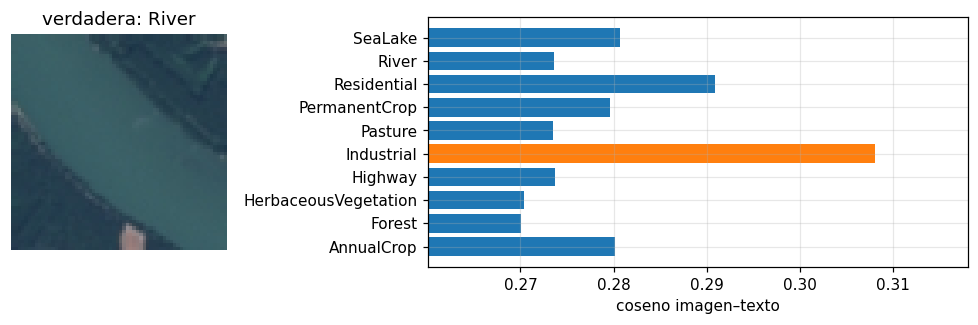

In [5]:
k = int((y_val == CLASSES.index('River')).nonzero()[0, 0]) if 'River' in CLASSES else 0
sim = (I_val[k] @ T_mejor.T)
np.savez_compressed('clip_zeroshot.npz', imagen=X_all[idx_val[k]].permute(1, 2, 0).numpy(), clases=np.array(CLASSES),
                    similitud=sim.numpy(), prob=(100 * sim).softmax(0).numpy(), verdadera=int(y_val[k]))
fig, (a0, a1) = plt.subplots(1, 2, figsize=(9, 3), gridspec_kw={'width_ratios': [1, 2.5]})
a0.imshow(X_all[idx_val[k]].permute(1, 2, 0)); a0.axis('off'); a0.set_title(f'verdadera: {CLASSES[int(y_val[k])]}')
a1.barh(CLASSES, sim.numpy(), color=['C1' if i == sim.argmax() else 'C0' for i in range(C)])
a1.set_xlim(sim.min().item() - 0.01, sim.max().item() + 0.01); a1.set_xlabel('coseno imagen–texto')
plt.tight_layout(); plt.show()

## 3. Las mismas features, con una sonda
¿El problema está en las features de CLIP o en los textos? Entrenamos la sonda lineal de la sesión 04 sobre los embeddings de imagen de CLIP con 1 % y 10 % de las etiquetas, y lo mismo con la ResNet-18 de ImageNet (sesión 03). Tres semillas por fracción.

In [6]:
def submuestra(y, frac, seed):
    g = torch.Generator().manual_seed(seed)
    return torch.cat([(y == c).nonzero().squeeze(1)[torch.randperm(int((y == c).sum()), generator=g)[:max(1, round(frac * int((y == c).sum())))]]
                      for c in range(C)])

def sonda(Htr, ytr, Hev, yev, pasos=300, seed=0):
    """La sonda lineal de la sesión 04: features estandarizadas, una capa lineal, Adam."""
    mu, sd = Htr.mean(0), Htr.std(0) + 1e-6
    torch.manual_seed(seed)
    W = nn.Linear(Htr.shape[1], C)
    opt = torch.optim.Adam(W.parameters(), lr=1e-2, weight_decay=1e-4)
    for _ in range(pasos):
        loss = F.cross_entropy(W((Htr - mu) / sd), ytr)
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        return (W((Hev - mu) / sd).argmax(1) == yev).float().mean().item()

@torch.no_grad()
def resnet_imagenet(X, chunk=500):
    w = ResNet18_Weights.IMAGENET1K_V1
    g = resnet18(weights=w).to(dev).eval(); g.fc = nn.Identity()
    m, s = torch.tensor(w.transforms().mean).view(1, 3, 1, 1).to(dev), torch.tensor(w.transforms().std).view(1, 3, 1, 1).to(dev)
    return torch.cat([g((X[i:i + chunk].to(dev).float() / 255 - m) / s).cpu() for i in range(0, len(X), chunk)])

y_train = y_all[idx_train]
H = {'CLIP (imagen)': (I_train, I_val), 'ResNet-18 ImageNet': (resnet_imagenet(X_all[idx_train]), resnet_imagenet(X_all[idx_val]))}
filas = [{'encoder': 'CLIP zero-shot', 'etiquetas': '0 %', 'accuracy': zs['una foto satelital de ...']}]
for nombre, (Htr, Hva) in H.items():
    for frac in (0.01, 0.10):
        accs = [sonda(Htr[i], y_train[i], Hva, y_val, seed=s) for s in (0, 1, 2) for i in [submuestra(y_train, frac, s)]]
        filas.append({'encoder': nombre + ' + sonda', 'etiquetas': f'{frac:.0%}', 'accuracy': float(np.mean(accs))})
tabla_eurosat = pd.DataFrame(filas)
print(tabla_eurosat.round(3).to_string(index=False))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 196MB/s]


                   encoder etiquetas  accuracy
            CLIP zero-shot       0 %     0.408
     CLIP (imagen) + sonda        1%     0.860
     CLIP (imagen) + sonda       10%     0.930
ResNet-18 ImageNet + sonda        1%     0.796
ResNet-18 ImageNet + sonda       10%     0.878


Compara con tu tabla del integrador de la sesión 04 (SimCLR sobre EuroSAT sin etiquetas, con 1 % y 10 %). Lo esperable: CLIP zero-shot está muy por encima del azar pero lejos de una sonda; con unas pocas etiquetas, la sonda sobre las **mismas** features de CLIP sube mucho. La información estaba en las features; el texto no llegaba a ella. Las fotos satelitales son raras entre los pies de foto de la web.

## 4. Bike Sharing y Chronos
Demanda de bicicletas por hora en Washington D. C., 2011–2012 (UCI), la serie del integrador de la sesión 05, con **sus mismos cortes, ventanas y horizontes**: validación de julio a septiembre de 2012, prueba de octubre a diciembre, ventanas de 72 horas que no cruzan un hueco, pronóstico a 1, 6, 12 y 24 horas desde la última hora de cada ventana. Así los números se comparan uno a uno con tu tabla del 5.6.

Chronos (diapositiva 57) escala cada serie, convierte sus valores en tokens y fue preentrenado como un modelo de lenguaje sobre muchas series, reales y sintéticas. Chronos-Bolt predice directamente varios cuantiles del futuro. Le damos las últimas 512 horas de demanda (sin clima ni calendario) y le pedimos las 24 siguientes.

In [2]:
URL_GITHUB = 'https://raw.githubusercontent.com/udacity/deep-learning-v2-pytorch/master/project-bikesharing/Bike-Sharing-Dataset/hour.csv'
URL_UCI = 'https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip'

def leer_hour():
    """Como en el integrador 5.6: data/ o /kaggle/input, si no GitHub, si no el zip de UCI."""
    import io, urllib.request, zipfile
    for root in [r for r in ROOTS if r.exists()]:
        hits = sorted(root.rglob('hour.csv'))
        if hits:
            return pd.read_csv(hits[0])
    try:
        with urllib.request.urlopen(URL_GITHUB, timeout=60) as r:
            return pd.read_csv(io.BytesIO(r.read()))
    except Exception:
        with urllib.request.urlopen(URL_UCI, timeout=120) as r:
            return pd.read_csv(io.BytesIO(zipfile.ZipFile(io.BytesIO(r.read())).read('hour.csv')))

crudo = leer_hour()
df = crudo.assign(t=pd.to_datetime(crudo['dteday']) + pd.to_timedelta(crudo['hr'], unit='h')).sort_values('t').reset_index(drop=True)
horas, cnt = df['t'].to_numpy(), df['cnt'].to_numpy(dtype=np.float32)

# los mismos cortes, ventanas y horizontes del integrador 5.6
T, HORIZONTES = 72, [1, 6, 12, 24]
H_MAX = max(HORIZONTES)
CORTES = {'val': np.datetime64('2012-07-01'), 'test': np.datetime64('2012-10-01')}
I_VAL, I_TEST = int(np.searchsorted(horas, CORTES['val'])), int(np.searchsorted(horas, CORTES['test']))

def ventanas(a, b):
    """Inicios i con la ventana i … i+T-1 y el objetivo más lejano dentro de [a, b), sin cruzar un hueco."""
    i = np.arange(a, b - (T - 1 + H_MAX))
    return i[(horas[i + T - 1 + H_MAX] - horas[i]) == np.timedelta64(T - 1 + H_MAX, 'h')]

va, te = ventanas(I_VAL, I_TEST), ventanas(I_TEST, len(horas))
serie = df.set_index('t')['cnt'].asfreq('h').interpolate()   # grilla regular: solo para el contexto de Chronos
pos = serie.index.get_indexer(df['t'])                          # fila de df → posición en la grilla
print(f'{len(df):,} horas registradas ({len(serie) - len(df)} faltan) · ventanas: validación {len(va):,}, prueba {len(te):,}')

17,379 horas registradas (165 faltan) · ventanas: validación 2,113, prueba 1,671


**Predice:** ¿le gana Chronos a la mejor línea base? ¿Y a tu red del 5.6, que además veía el clima y el calendario? ¿En qué horizontes?

In [3]:
def objetivos(ini):
    return np.stack([cnt[ini + T - 1 + h] for h in HORIZONTES], 1)            # (n, 4) bicicletas

def base_persistencia(ini):
    return np.stack([cnt[ini + T - 1]] * len(HORIZONTES), 1)                  # lo mismo que ahora

def base_ayer(ini):
    return np.stack([cnt[ini + T - 1 + h - 24] for h in HORIZONTES], 1)       # la misma hora de ayer

CONTEXTO = 512                                                                # horas de historia para Chronos
chronos = BaseChronosPipeline.from_pretrained('amazon/chronos-bolt-small', device_map=dev, torch_dtype=torch.float32)

def pronosticar(ini, B=256):
    """Cuantiles 0.1, 0.5, 0.9 de las 24 horas siguientes a cada origen (la última hora de la ventana): sin entrenar."""
    v = serie.to_numpy(dtype=np.float32)
    origen = pos[ini + T - 1]
    qs = []
    for k in range(0, len(origen), B):
        ctx = torch.tensor(np.stack([v[j + 1 - CONTEXTO:j + 1] for j in origen[k:k + B]]))
        q, _ = chronos.predict_quantiles(ctx, prediction_length=H_MAX, quantile_levels=[0.1, 0.5, 0.9])
        qs.append(q.float().cpu().numpy())
    return np.concatenate(qs)[:, [h - 1 for h in HORIZONTES]]               # (n, 4, 3)

t0 = time.time()
Q_va, Q_te = pronosticar(va), pronosticar(te)
print(f'{len(va) + len(te):,} pronósticos en {time.time() - t0:.1f} s')

config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  191MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

3,784 pronósticos en 66.6 s


## 5. ¿Le gana a la base? ¿Y a tu red?
MAE por horizonte, en bicicletas por hora, contra las dos líneas base del 5.6. Escribe en `MI_RED_56` tu MAE de **validación** por horizonte del integrador 5.6 (la tabla del TODO 3) para tenerlo en la misma tabla. También: si el intervalo 10–90 % contiene al valor real con la frecuencia que promete.

Validación (julio–septiembre de 2012), MAE en bicicletas por hora:
               persistencia  misma hora de ayer  Chronos-Bolt zero-shot  mejora sobre la mejor base
horizonte (h)                                                                                      
1                 96.010002           84.059998               29.900000                        0.64
6                298.880005           83.930000               41.900002                        0.50
12               310.730011           83.419998               43.480000                        0.48
24                82.900002           82.900002               42.320000                        0.49

Prueba (octubre–diciembre de 2012):
               persistencia  misma hora de ayer  Chronos-Bolt zero-shot  mejora sobre la mejor base
horizonte (h)                                                                                      
1                 78.970001           75.949997               26.400000                        0

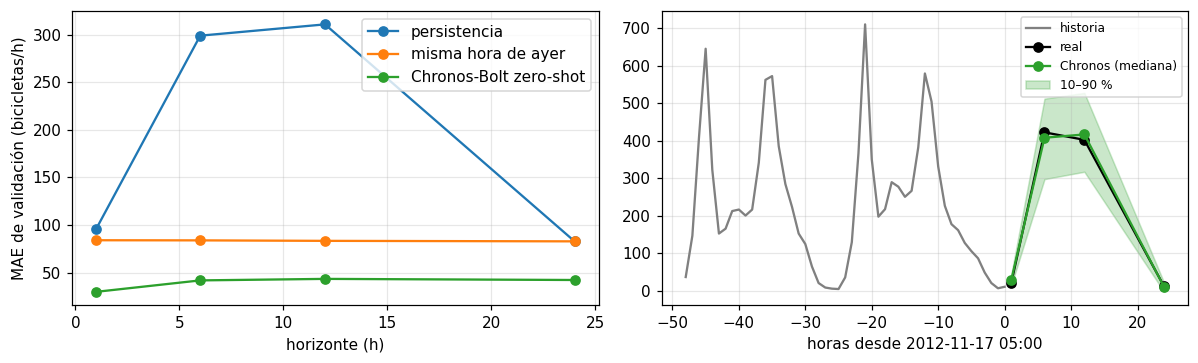

In [6]:
def tabla(ini, Q):
    real = objetivos(ini)
    mae = lambda p: np.abs(p - real).mean(0)
    t = pd.DataFrame({'persistencia': mae(base_persistencia(ini)), 'misma hora de ayer': mae(base_ayer(ini)),
                      'Chronos-Bolt zero-shot': mae(Q[..., 1])}, index=pd.Index(HORIZONTES, name='horizonte (h)'))
    t['mejora sobre la mejor base'] = 1 - t['Chronos-Bolt zero-shot'] / t[['persistencia', 'misma hora de ayer']].min(1)
    return t

tab_va, tab_te = tabla(va, Q_va), tabla(te, Q_te)
MI_RED_56 = {1: None, 6: None, 12: None, 24: None}     # tu MAE de VALIDACIÓN por horizonte en el integrador 5.6
if all(v is not None for v in MI_RED_56.values()):
    tab_va['mi red del 5.6 (con clima)'] = pd.Series(MI_RED_56)
print('Validación (julio–septiembre de 2012), MAE en bicicletas por hora:')
print(tab_va.round(2).to_string())
print('\nPrueba (octubre–diciembre de 2012):')
print(tab_te.round(2).to_string())
real_te = objetivos(te)
cobertura = float(((real_te >= Q_te[..., 0]) & (real_te <= Q_te[..., 2])).mean())
print(f'\nen prueba, el intervalo 10–90 % de Chronos contiene el valor real el {cobertura:.0%} de las veces (ideal: 80 %)')

fig, (a0, a1) = plt.subplots(1, 2, figsize=(11, 3.4))
tab_va.drop(columns='mejora sobre la mejor base').plot(ax=a0, marker='o'); a0.set_ylabel('MAE de validación (bicicletas/h)')
j = len(te) // 2; o = te[j] + T - 1
a1.plot(np.arange(-48, 1), cnt[o - 48:o + 1], color='gray', label='historia')
a1.plot(HORIZONTES, real_te[j], 'ko-', label='real')
a1.plot(HORIZONTES, Q_te[j, :, 1], 'o-', color='C2', label='Chronos (mediana)')
a1.fill_between(HORIZONTES, Q_te[j, :, 0], Q_te[j, :, 2], color='C2', alpha=0.25, label='10–90 %')
a1.set_xlabel(f'horas desde {pd.Timestamp(horas[o]):%Y-%m-%d %H:%M}'); a1.legend(fontsize=8)
plt.tight_layout(); plt.show()

Chronos solo ve la demanda: no sabe del clima, de los festivos ni de que es fin de semana, que tu red del 5.6 sí usaba, y nunca se entrenó con esta serie. Si le gana a tu red, el preentrenamiento sobre muchas series vale más que esas variables; si no, la diapositiva 58 tenía razón: zero-shot es una afirmación que hay que comprobar contra lo que ya tienes.

In [ ]:
res = {}
if 'zs' in globals():                                                         # secciones 1-3 corridas
    res['eurosat'] = {'zero_shot': zs, 'tabla': tabla_eurosat.to_dict('records')}
if 'tab_va' in globals():                                                     # secciones 4-5 corridas
    res['bike'] = {'protocolo': 'ventanas, cortes y horizontes del integrador 5.6', 'contexto': CONTEXTO,
                   'validacion': tab_va.reset_index().to_dict('records'), 'prueba': tab_te.reset_index().to_dict('records'),
                   'cobertura_10_90_prueba': cobertura, 'ventanas': {'validacion': len(va), 'prueba': len(te)}}
json.dump(res, open('resultados_fundacionales.json', 'w'), ensure_ascii=False, indent=1)
print('guardado: resultados_fundacionales.json con', ' y '.join(res) or 'nada (corre primero las secciones)')

## Tu turno
1. **Otra plantilla.** Escribe tus propios textos para las 10 clases (en inglés). ¿Cuánto puedes subir el zero-shot? ¿Por qué eso ya no es "cero" etiquetas?
2. **Contexto.** Chronos con `CONTEXTO = 48` y `CONTEXTO = 2048`. ¿Cuánta historia necesita para ver el ciclo semanal?
3. **Más contexto que tu red.** Tu red del 5.6 veía 72 horas; Chronos, 512. Dale a Chronos `CONTEXTO = 72`: ¿cuánto de su ventaja venía de ver más historia?
4. **Un modelo más grande.** `amazon/chronos-bolt-base` y `openai/clip-vit-large-patch14`. ¿Cuánto mejora, y cuánto más tarda?

In [11]:
# Tu turno

### Referencias
- Radford et al. (2021), *Learning Transferable Visual Models From Natural Language Supervision*, ICML (CLIP).
- Ansari et al. (2024), *Chronos: Learning the Language of Time Series*, TMLR; Chronos-Bolt, Amazon Science (2024).
- Helber et al. (2019), *EuroSAT: A Novel Dataset and Deep Learning Benchmark for Land Use and Land Cover Classification*, IEEE JSTARS.
- Fanaee-T y Gama (2014), *Event labeling combining ensemble detectors and background knowledge*, Progress in AI (Bike Sharing, UCI).